In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.notebook import tqdm

In [2]:
df = pd.read_csv('data/AB_Test_Results.csv')

## Разбор данных

In [3]:
df.head(5)

,USER_ID,VARIANT_NAME,REVENUE
0,737,variant,0.0
1,2423,control,0.0
2,9411,control,0.0
3,7311,control,0.0
4,6174,variant,0.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   USER_ID       10000 non-null  int64  
 1   VARIANT_NAME  10000 non-null  str    
 2   REVENUE       10000 non-null  float64
dtypes: float64(1), int64(1), str(1)
memory usage: 234.5 KB


> Проверка сплитования

In [5]:
np.any(df['USER_ID'].duplicated())

np.True_

In [6]:
len(df['USER_ID'].unique()) < df.groupby('VARIANT_NAME')['USER_ID'].unique().apply(lambda x: len(x)).sum()

np.True_

> Есть пользователи, которые относятся одновременно и к тесту, и к контролю. Вероятно, какая-то ошибка при сплитовании. Невозможно по имеющимся данным определить, к какой группе на самом деле относились пользователи, поэтому признаем данные об этих пользователях невалидными, и исключаем их из анализа

In [7]:
## получаем список user_id, которые есть как в контроле, так и тесте 
ids = set(df.loc[df['VARIANT_NAME'] == 'variant', 'USER_ID']).intersection(set(df.loc[df['VARIANT_NAME'] != 'variant', 'USER_ID']))
len(ids)

1541

In [8]:
print(f"Доля невалидных пользователей: {len(ids) / len(df['USER_ID'].unique())}")

Доля невалидных пользователей: 0.24367488931056294


> Удаляем почти четверть выборки. MDE должен сильно вырасти  

In [9]:
df = df[~df['USER_ID'].isin(ids)]

In [10]:
## Проверка того, что теперь нет user_id, которые одновременно и в тесте, и в контроле
len(df['USER_ID'].unique()) == df.groupby('VARIANT_NAME')['USER_ID'].unique().apply(lambda x: len(x)).sum()

np.True_

> Проверяем, агрегированы ли данные по пользователям изначально, или работаем с сессиями

In [11]:
df.loc[df['USER_ID'] == 5652]

,USER_ID,VARIANT_NAME,REVENUE
595,5652,control,0.0
778,5652,control,0.0
2880,5652,control,0.0
6327,5652,control,0.0
7248,5652,control,0.0
7972,5652,control,0.0


In [12]:
df.loc[df['USER_ID'] == 2166]

,USER_ID,VARIANT_NAME,REVENUE
8153,2166,control,0.00
8168,2166,control,29.32


> В данных пользовательские сессии, а не суммарный revenue пользователя за весь период теста

## Проверка гипотезы $H_0$: ARPU не изменился на уровне значимости $\alpha$ = 0.05

In [13]:
## Группируем данные по пользователям
data = df.groupby(['VARIANT_NAME', 'USER_ID'])['REVENUE'].sum()

In [14]:
print("Размеры групп:")
df.groupby('VARIANT_NAME')['USER_ID'].nunique()

Размеры групп:


VARIANT_NAME
control    2390
variant    2393
Name: USER_ID, dtype: int64

> Почти равные по размерам группы

In [15]:
a = data['control'].values
b = data['variant'].values

In [16]:
rng = np.random.default_rng(seed=42)
## Бутсреп на 100_000 итерациях
num_samples=100000
size_control = len(a)
size_test = len(b)

mean_diff=[]
for _ in tqdm(range(num_samples)):
    control = rng.choice(a, size=size_control, replace=True)
    test = rng.choice(b, size=size_test, replace=True)
    mean_diff.append(test.mean()-control.mean())

mean_diff = np.array(mean_diff)

  0%|          | 0/100000 [00:00<?, ?it/s]

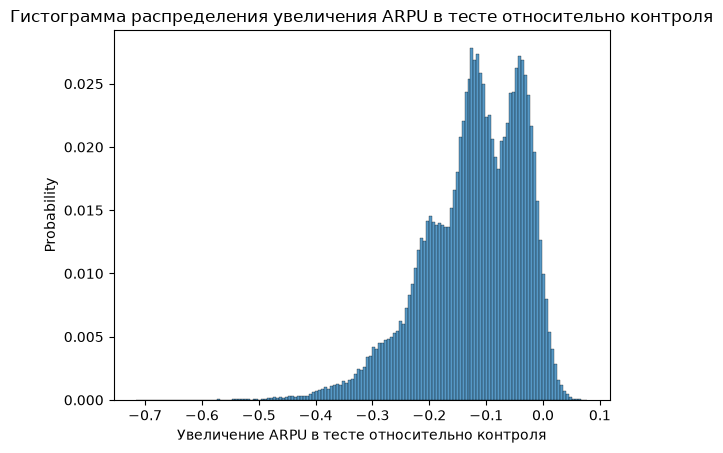

In [17]:
plt.title('Гистограмма распределения увеличения ARPU в тесте относительно контроля')
sns.histplot(mean_diff, stat='probability')
plt.xlabel('Увеличение ARPU в тесте относительно контроля');

> Бимодальное распределение. По ЦПТ должно быть приближенным к нормальному

In [18]:
data.reset_index().groupby('VARIANT_NAME')['REVENUE'].var()

VARIANT_NAME
control    17.407264
variant     0.736520
Name: REVENUE, dtype: float64

> Дисперсии отличаются более чем в 17 раз

In [19]:
np.sort(a)[-10:]

array([  9.99,  10.63,  11.98,  14.07,  14.24,  17.05,  18.56,  20.07,
        29.32, 196.01])

In [20]:
np.sort(b)[-10:]


array([ 4.52,  5.08,  5.98,  7.27,  8.7 , 10.82, 12.99, 12.99, 19.47,
       23.04])

> В контрольной группе есть пользователь с очень большим суммарным revenue. Предполагаю, что бимодальность вызвана им.

In [21]:
alpha = 0.05
effect = b.mean() - a.mean()
rel_effect = effect / a.mean() * 100

print("Абсолютное значение наблюдаемого эффекта:  %.3f"%effect)
print('Относительное значение наблюдаемого эффекта:  %.1f %%'%rel_effect)

Абсолютное значение наблюдаемого эффекта:  -0.122
Относительное значение наблюдаемого эффекта:  -61.9 %


> Наблюдаем эффект: ARPU в тесте -62% по сравнению с контролем

## Доверительный интервал

In [22]:
l = np.quantile(mean_diff, alpha/2)
r = np.quantile(mean_diff, 1-alpha/2)

print("Доверительный интервал прироста ARPU в тестовой выборке относительно контроля с уровнем доверия 95%")
print("[%.3f, %.3f]"%(l, r))

Доверительный интервал прироста ARPU в тестовой выборке относительно контроля с уровнем доверия 95%
[-0.322, 0.004]


> 0 входит в доверительный интервал -> нет оснований отвергнуть нулевую гипотезу на текущем уровне значимости